<a href="https://colab.research.google.com/github/Eton-np/DataMining/blob/main/Project_DataMining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,
                             roc_auc_score,average_precision_score,classification_report,confusion_matrix,
                             ConfusionMatrixDisplay,RocCurveDisplay,PrecisionRecallDisplay)

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/DataSet/online_shoppers_intention.csv')
df.head(10)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
5,0,0.0,0,0.0,19,154.216667,0.015789,0.024561,0.0,0.0,Feb,2,2,1,3,Returning_Visitor,False,False
6,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.4,Feb,2,4,3,3,Returning_Visitor,False,False
7,1,0.0,0,0.0,0,0.000000,0.200000,0.200000,0.0,0.0,Feb,1,2,1,5,Returning_Visitor,True,False
8,0,0.0,0,0.0,2,37.000000,0.000000,0.100000,0.0,0.8,Feb,2,2,2,3,Returning_Visitor,False,False
9,0,0.0,0,0.0,3,738.000000,0.000000,0.022222,0.0,0.4,Feb,2,4,1,2,Returning_Visitor,False,False


In [ ]:
df.shape

(12330, 18)

In [ ]:
#ดูชนิดข้อมูล
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

1. Administrative
จำนวนหน้าหมวดการจัดการหรือธุรการที่ผู้เข้าชมเว็บไซต์เปิดดู เช่น หน้าบัญชีผู้ใช้หรือข้อมูลส่วนตัว

2. Administrative_Duration
ระยะเวลารวมที่ผู้เข้าชมใช้ในการดูหน้า Administrative หน่วยเป็นวินาที

3. Informational
จำนวนหน้าข้อมูลทั่วไปที่ผู้เข้าชมเว็บไซต์เปิดดู เช่น หน้าเกี่ยวกับบริษัทหรือข้อมูลบริการ

4. Informational_Duration
ระยะเวลารวมที่ผู้เข้าชมใช้ในการดูหน้า Informational หน่วยเป็นวินาที

5. ProductRelated
จำนวนหน้าที่เกี่ยวข้องกับสินค้าที่ผู้เข้าชมเว็บไซต์เปิดดู

6. ProductRelated_Duration
ระยะเวลารวมที่ผู้เข้าชมใช้ในการดูหน้าสินค้า หน่วยเป็นวินาที

7. BounceRates
อัตราการเข้าชมหน้าเว็บไซต์แล้วออกจากเว็บไซต์โดยไม่มีการเข้าชมหน้าหรือโต้ตอบต่อ

8. ExitRates
อัตราการออกจากเว็บไซต์จากหน้าเว็บนั้น เมื่อเทียบกับจำนวนการดูหน้านั้นทั้งหมด

9. PageValues
ค่าประมาณของมูลค่าหน้าเว็บไซต์ที่มีส่วนช่วยให้เกิดการทำธุรกรรมหรือการซื้อสินค้า

10. SpecialDay
ค่าที่แสดงระดับความใกล้เคียงกับวันสำคัญหรือเทศกาล เช่น วันวาเลนไทน์ โดยมีค่าตั้งแต่ 0 ถึง 1

11. Month
เดือนที่ผู้เข้าชมเว็บไซต์

12. OperatingSystems
รหัสระบบปฏิบัติการที่ผู้เข้าชมเว็บไซต์ใช้งาน

13. Browser
รหัสเว็บเบราว์เซอร์ที่ผู้เข้าชมเว็บไซต์ใช้งาน

14. Region
รหัสภูมิภาคหรือพื้นที่ของผู้เข้าชมเว็บไซต์

15. TrafficType
รหัสประเภทแหล่งที่มาของ Traffic ที่นำผู้เข้าชมมายังเว็บไซต์

16. VisitorType
ประเภทของผู้เข้าชมเว็บไซต์ เช่น ผู้เข้าชมใหม่ (New Visitor) หรือผู้เข้าชมซ้ำ (Returning Visitor)

17. Weekend
ระบุว่าการเข้าชมเว็บไซต์เกิดขึ้นในวันเสาร์หรือวันอาทิตย์หรือไม่
True = วันหยุดสุดสัปดาห์
False = วันธรรมดา

18. Revenue
ตัวแปรเป้าหมาย (Target Variable) ใช้ระบุว่าผู้เข้าชมเว็บไซต์ทำการซื้อสินค้าหรือไม่
True = มีการซื้อสินค้า
False = ไม่มีการซื้อสินค้า

In [ ]:
#ดูcolumnที่มีnull
df.isnull().sum()

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


In [ ]:
#ดูค่าทางสถิติ
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [ ]:
#ดูแถวซ้ำ
print(df.duplicated().sum())

125


In [ ]:
#เลือกcolumnเฉพาะที่เป็นตัวเลข
num_col = df.select_dtypes(include=["number"]).columns

#ดูว่าเลขติดลบไหม
negative = (df[num_col] < 0).sum()

print(negative)

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
dtype: int64


In [ ]:
df2 = df.copy()

In [ ]:
print(df2.duplicated().sum())

125


In [ ]:
#เช็คแถวซ้ำก่อนลบ
before = len(df2)

#ลบแถวซ้ำ
df2 = df2.drop_duplicates()

# Reset index
df2 = df2.reset_index(drop=True)

#เช็คแถวซ้ำหลังลบ
after = len(df2)

print("Rows Before Cleaning:", before)
print("Rows After Cleaning:", after)
print("Duplicate Rows Removed:", before - after)

Rows Before Cleaning: 12330
Rows After Cleaning: 12205
Duplicate Rows Removed: 125


In [ ]:
print(df2.duplicated().sum())

0


Revenue
False    10297
True      1908
Name: count, dtype: int64


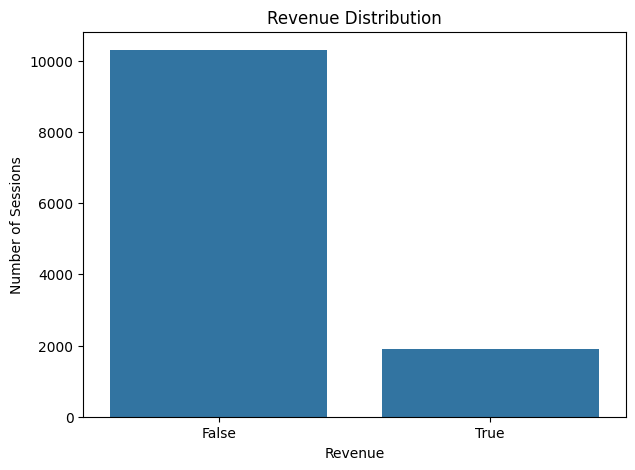

In [ ]:
#ดูเปรียบเทียบจำนวนคนที่ซื้อกับไม่ซื้อ
print(df2["Revenue"].value_counts())

plt.figure(figsize=(7, 5))

sns.countplot(data=df2,x="Revenue")

plt.title("Revenue Distribution")
plt.xlabel("Revenue")
plt.ylabel("Number of Sessions")

plt.show()
#Dataชุดนี้มีปัญหาเรื่องclass imbalance

In [ ]:
print(df2["VisitorType"].value_counts())

VisitorType
Returning_Visitor    10431
New_Visitor           1693
Other                   81
Name: count, dtype: int64


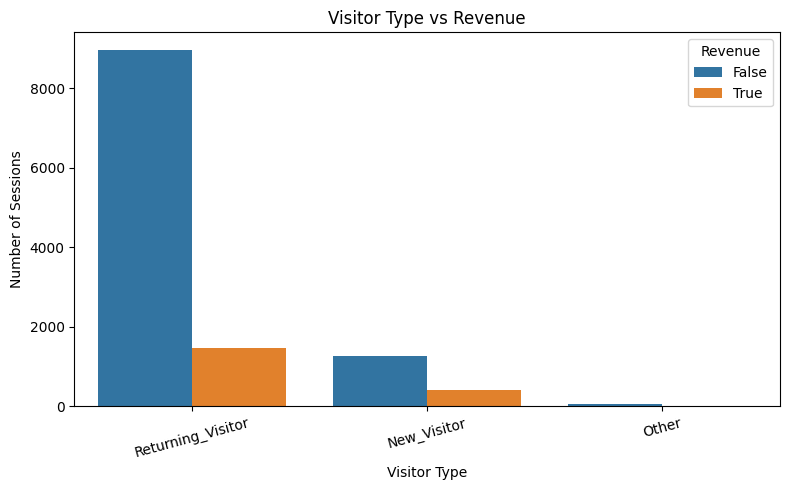

In [ ]:
#ดูเปรียบเทียบจำนวนคนที่ซื้อกับไม่ซื้อแต่ละประเภท
plt.figure(figsize=(8, 5))

sns.countplot(data=df2,x="VisitorType",hue="Revenue")

plt.title("Visitor Type vs Revenue")
plt.xlabel("Visitor Type")
plt.ylabel("Number of Sessions")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

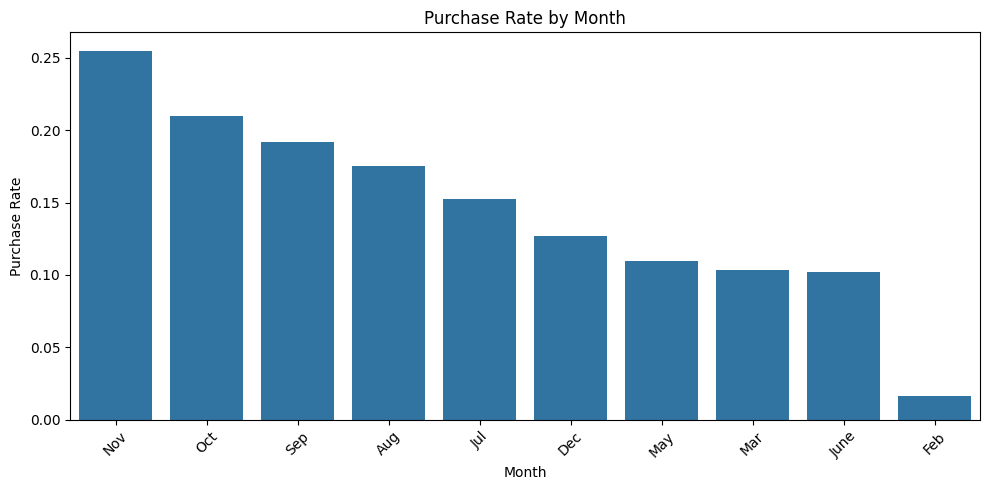

In [ ]:
#ดูการซื้อในแต่ละเดือน
monthly_revenue = (df2.groupby("Month")["Revenue"].mean().sort_values(ascending=False))

plt.figure(figsize=(10, 5))

sns.barplot(x=monthly_revenue.index,y=monthly_revenue.values)

plt.title("Purchase Rate by Month")
plt.xlabel("Month")
plt.ylabel("Purchase Rate")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

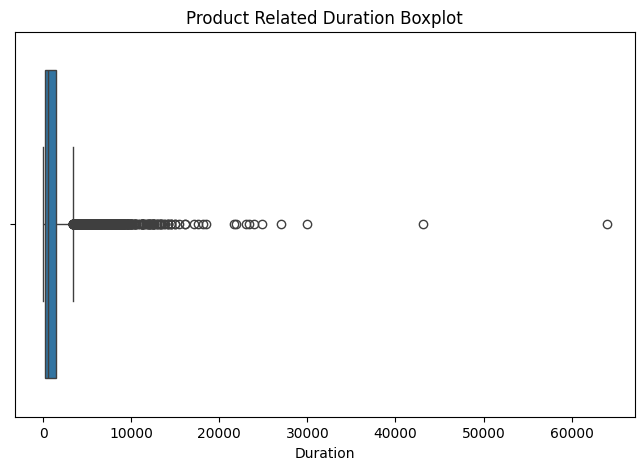

In [ ]:
#ดูระยะเวลาเข้าชมสินค้า
plt.figure(figsize=(8, 5))

sns.boxplot(data=df2, x="ProductRelated_Duration")

plt.title("Product Related Duration Boxplot")
plt.xlabel("Duration")

plt.show()

In [ ]:
# ดูPurchase Rate แยกตาม VisitorType

visitor_purchase = (df2.groupby("VisitorType")["Revenue"].agg(
        Sessions="count",
        Purchases="sum",
        Purchase_Rate="mean").reset_index())


visitor_purchase["Purchase_Rate"] *= 100


visitor_purchase = visitor_purchase.sort_values(by="Purchase_Rate",ascending=False)

# แสดงผลลัพธ์
display(visitor_purchase)


,VisitorType,Sessions,Purchases,Purchase_Rate
0,New_Visitor,1693,422,24.926167
1,Other,81,16,19.753086
2,Returning_Visitor,10431,1470,14.092609


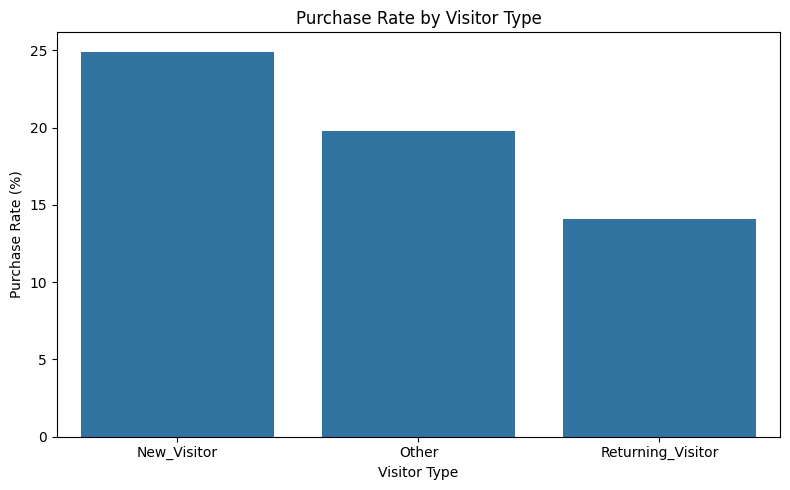

In [ ]:
# แสดง Purchase Rate ของแต่ละ VisitorType

plt.figure(figsize=(8, 5))

sns.barplot(
    data=visitor_purchase,
    x="VisitorType",
    y="Purchase_Rate"
)

plt.title("Purchase Rate by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Purchase Rate (%)")

plt.tight_layout()
plt.show()


In [ ]:
num_cols = df2.select_dtypes(include=["number"]).columns.drop(["OperatingSystems", "Browser", "Region", "TrafficType"],errors="ignore")

#หาOutlier ด้วย IQR
for col in num_cols:
    Q1 = df2[col].quantile(0.25)
    Q3 = df2[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df2[(df2[col] < lower) | (df2[col] > upper)]

    print(f"{col}: {len(outliers)} outliers")
#หลายcolumnมีoutliersค่อนข้างสูงโดยเฉพาะInformational,PageValuesและInformational_Duration
#ค่าดังกล่าวอาจเป็นพฤติกรรมการเข้าชมเว็บไซต์ที่เกิดขึ้นจริงเลยตัดสินใจเก็บข้อมูลoutliersไว้ทั้งหมด

Administrative: 404 outliers
Administrative_Duration: 1149 outliers
Informational: 2631 outliers
Informational_Duration: 2405 outliers
ProductRelated: 1007 outliers
ProductRelated_Duration: 951 outliers
BounceRates: 1428 outliers
ExitRates: 1325 outliers
PageValues: 2730 outliers
SpecialDay: 1249 outliers


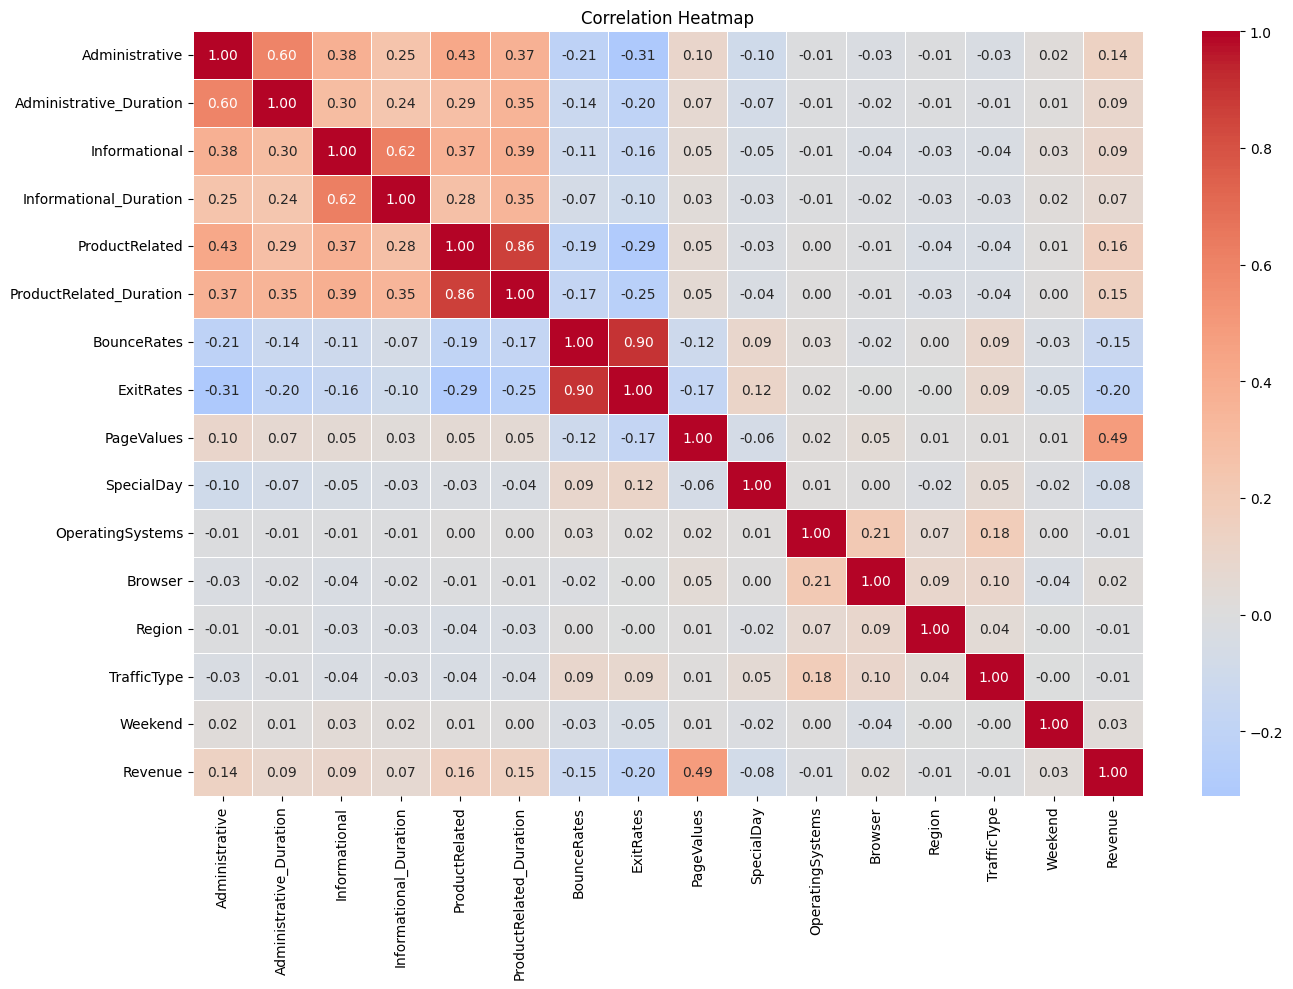

In [ ]:
#ดูค่าcorrelationด้วยheatmap
df2["Revenue"] = df2["Revenue"].astype(int)

corr = df2.corr(numeric_only=True)

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
#ดูความสัมพันธ์ของแต่ละ Feature กับ Revenue
revenue_corr = corr["Revenue"].drop("Revenue")

#เรียงลำดับตามความสัมพันธ์มากไปน้อย
revenue_corr = revenue_corr.reindex(
    revenue_corr.abs().sort_values(ascending=False).index
)


result = pd.DataFrame({
    "Feature": revenue_corr.index,
    "Correlation": revenue_corr.values,
    "Relationship": [
        "Positive" if x > 0
        else "Negative"
        if x < 0
        else "No correlation"
        for x in revenue_corr.values
    ]
})

display(result.head(5))


,Feature,Correlation,Relationship
0,PageValues,0.491894,Positive
1,ExitRates,-0.204320,Negative
2,ProductRelated,0.156042,Positive
3,ProductRelated_Duration,0.150077,Positive
4,BounceRates,-0.145091,Negative


In [ ]:
#เลือกcolumnที่เป็นcategory
category_cols = ["Month","OperatingSystems","Browser","Region","TrafficType","VisitorType","Weekend"]

#แบ่งfeatureกับtarget
X = df2.drop(columns=["Revenue"])

y = df2["Revenue"].astype(int)

#columnที่เป็นcategoryที่เป็นตัวเลขให้เป็นstringถ้าไม่แปลงโมเดลอาจมองเป็นข้อมูลตัวเลขซึ่งมีลำดับและระยะห่างระหว่างค่า
for col in category_cols:
    X[col] = X[col].astype(str)
    #แบ่งtrain test
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [ ]:
!pip install catboost
from catboost import CatBoostClassifier

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 42.0 MB/s  0:00:02


In [ ]:
#สร้างmodel
cat_model = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=100,
)
cat_model.fit(
    X_train,
    y_train,
    cat_features=category_cols
)

0:	total: 48.3ms	remaining: 48.2s
100:	total: 3.62s	remaining: 32.2s
200:	total: 9.66s	remaining: 38.4s
300:	total: 14.3s	remaining: 33.3s
400:	total: 16.7s	remaining: 25s
500:	total: 19.1s	remaining: 19s
600:	total: 21.5s	remaining: 14.2s
700:	total: 25s	remaining: 10.6s
800:	total: 28.2s	remaining: 7s
900:	total: 30.6s	remaining: 3.36s
999:	total: 32.9s	remaining: 0us


CatBoostClassifier(auto_class_weights='Balanced', depth=6, eval_metric='AUC', iterations=1000, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

* iterations=1000	จำนวนรอบในการเรียนรู้
* learning_rate=0.05	อัตราการเรียนรู้
* depth=6	ความลึกของ Decision Tree
* loss_function	ฟังก์ชันคำนวณความผิดพลาด
* eval_metric="AUC"	ใช้ AUC ประเมินระหว่างฝึก
* auto_class_weights	ช่วยจัดการ Class Imbalance
* random_seed=42	กำหนดค่าเริ่มต้นการสุ่ม
* verbose=100	แสดงผลทุก 100 รอบ

In [ ]:
#ทำนาย
y_pred = cat_model.predict(X_test)

In [ ]:
#ประเมินผล
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8738222040147481

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.90      0.92      2059
           1       0.57      0.75      0.65       382

    accuracy                           0.87      2441
   macro avg       0.76      0.82      0.79      2441
weighted avg       0.89      0.87      0.88      2441



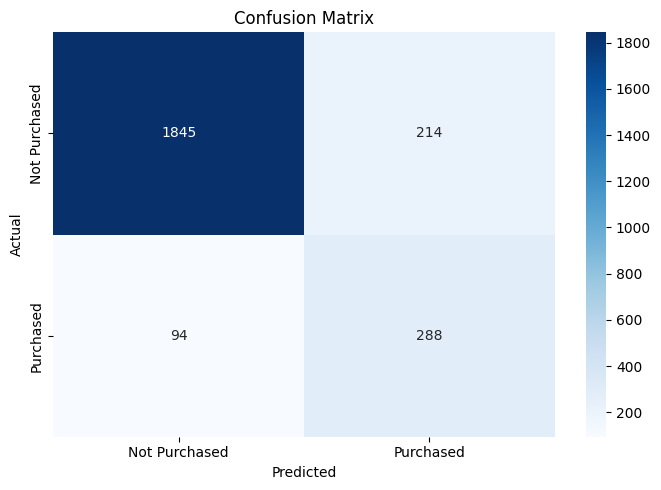

In [ ]:
#คำนวณหาConfusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Purchased", "Purchased"],
    yticklabels=["Not Purchased", "Purchased"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import RobustScaler

X_train_lr = X_train.copy()
X_test_lr = X_test.copy()

#แยกเอาเฉพาะfeatureที่เป็นตัวเลข
numeric_cols = [
    col for col in X_train_lr.columns
    if col not in category_cols
]

# One-Hot Encoding
X_train_lr = pd.get_dummies(X_train_lr,columns=category_cols,dtype=int)

X_test_lr = pd.get_dummies(X_test_lr,columns=category_cols,dtype=int)

#จัดเรียงcolumnของtestใหม่ให้ตรงกับtrain
X_test_lr = X_test_lr.reindex(columns=X_train_lr.columns,fill_value=0)


scaler = RobustScaler()
X_train_lr[numeric_cols] = scaler.fit_transform(X_train_lr[numeric_cols])
X_test_lr[numeric_cols] = scaler.transform(X_test_lr[numeric_cols])

In [ ]:
from sklearn.linear_model import LogisticRegression


Logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=3000,
    random_state=42,
    n_jobs=-1
)

Logistic_model.fit(X_train_lr, y_train)

y_pred_lr = Logistic_model.predict(X_test_lr)


print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test,y_pred_lr))

Accuracy: 0.8471937730438345

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.86      0.90      2059
           1       0.51      0.80      0.62       382

    accuracy                           0.85      2441
   macro avg       0.73      0.83      0.76      2441
weighted avg       0.89      0.85      0.86      2441


Confusion Matrix:
[[1764  295]
 [  78  304]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# One-Hot Encoding
X_train_rf = pd.get_dummies(X_train,columns=category_cols,dtype=int)

X_test_rf = pd.get_dummies(X_test,columns=category_cols,dtype=int)


X_test_rf = X_test_rf.reindex(columns=X_train_rf.columns,fill_value=0)

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_rf,y_train)

y_pred_rf = rf_model.predict(X_test_rf)


print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test,y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test,y_pred_rf))

Accuracy: 0.896763621466612

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.97      0.94      2059
           1       0.74      0.52      0.61       382

    accuracy                           0.90      2441
   macro avg       0.83      0.74      0.78      2441
weighted avg       0.89      0.90      0.89      2441


Confusion Matrix:
[[1989   70]
 [ 182  200]]


In [ ]:
from xgboost import XGBClassifier

X_train_xgb = X_train_rf.copy()
X_test_xgb = X_test_rf.copy()

y_train_xgb = y_train.astype(int)
y_test_xgb = y_test.astype(int)

negative_count = (y_train_xgb == 0).sum()
positive_count = (y_train_xgb == 1).sum()

scale_pos_weight = negative_count / positive_count

XGB_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

XGB_model.fit(X_train_xgb,y_train_xgb)


y_pred_xgb = XGB_model.predict(X_test_xgb)

print("Accuracy:",accuracy_score(y_test_xgb, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(y_test_xgb,y_pred_xgb,target_names=["Not Purchased", "Purchased"]))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_xgb,y_pred_xgb))

Accuracy: 0.8762802130274477

Classification Report:
               precision    recall  f1-score   support

Not Purchased       0.96      0.89      0.92      2059
    Purchased       0.58      0.78      0.66       382

     accuracy                           0.88      2441
    macro avg       0.77      0.84      0.79      2441
 weighted avg       0.90      0.88      0.88      2441


Confusion Matrix:
[[1841  218]
 [  84  298]]


In [ ]:
from sklearn.tree import DecisionTreeClassifier
X_train_dt = X_train_rf.copy()
X_test_dt = X_test_rf.copy()


DT_model = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)


DT_model.fit(X_train_dt,y_train)

y_pred_dt = DT_model.predict(X_test_dt)

print("Accuracy:",accuracy_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test,y_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test,y_pred_dt))

Accuracy: 0.8488324457189677

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.92      0.91      2059
           1       0.52      0.49      0.50       382

    accuracy                           0.85      2441
   macro avg       0.71      0.70      0.71      2441
weighted avg       0.85      0.85      0.85      2441


Confusion Matrix:
[[1885  174]
 [ 195  187]]


In [ ]:
#เก็บPredictionของแต่ละModel
models = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb,
    "CatBoost": y_pred
}

results = []

for model_name, predictions in models.items():
    predictions = np.asarray(predictions).ravel()
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, pos_label=1, zero_division=0
        )
    })


model_comparison = pd.DataFrame(results)


model_comparison = model_comparison.sort_values(by="F1-Score",ascending=False).reset_index(drop=True)


display(model_comparison.round(4))


,Model,Accuracy,Precision,Recall,F1-Score
0,XGBoost,0.8763,0.5775,0.7801,0.6637
1,CatBoost,0.8738,0.5737,0.7539,0.6516
2,Logistic Regression,0.8472,0.5075,0.7958,0.6198
3,Random Forest,0.8968,0.7407,0.5236,0.6135
4,Decision Tree,0.8488,0.5180,0.4895,0.5034


In [ ]:
feature_importance = pd.DataFrame({"Feature": X_train.columns,"Importance": cat_model.feature_importances_})
feature_importance = feature_importance.sort_values(by="Importance",ascending=False)
print(feature_importance.head(5))

                    Feature  Importance
10                    Month   22.200315
8                PageValues   17.747602
5   ProductRelated_Duration    9.622759
7                 ExitRates    7.867045
1   Administrative_Duration    5.795204


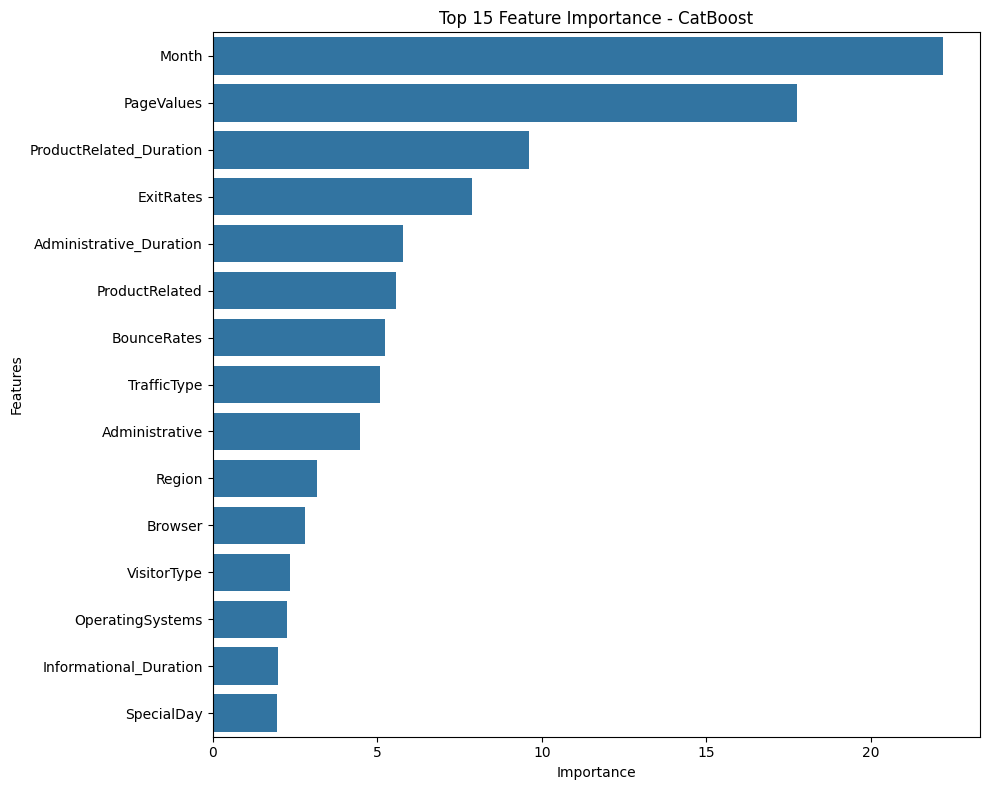

In [ ]:
plt.figure(figsize=(10, 8))

sns.barplot(data=feature_importance.head(15),x="Importance",y="Feature")

plt.title("Top 15 Feature Importance - CatBoost")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [ ]:
xgb_importance = pd.DataFrame({
    "Encoded_Feature": X_train_xgb.columns,
    "Importance": XGB_model.feature_importances_
})

def get_original_feature(feature):
    for col in category_cols:
        if feature.startswith(col + "_"):
            return col
    return feature

xgb_importance["Feature"] = (
    xgb_importance["Encoded_Feature"]
    .apply(get_original_feature)
)

xgb_feature_importance = (
    xgb_importance.groupby("Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(xgb_feature_importance.head(5))


,Feature,Importance
0,Month,0.264660
1,PageValues,0.159483
2,TrafficType,0.141975
3,Browser,0.102504
4,Region,0.095208


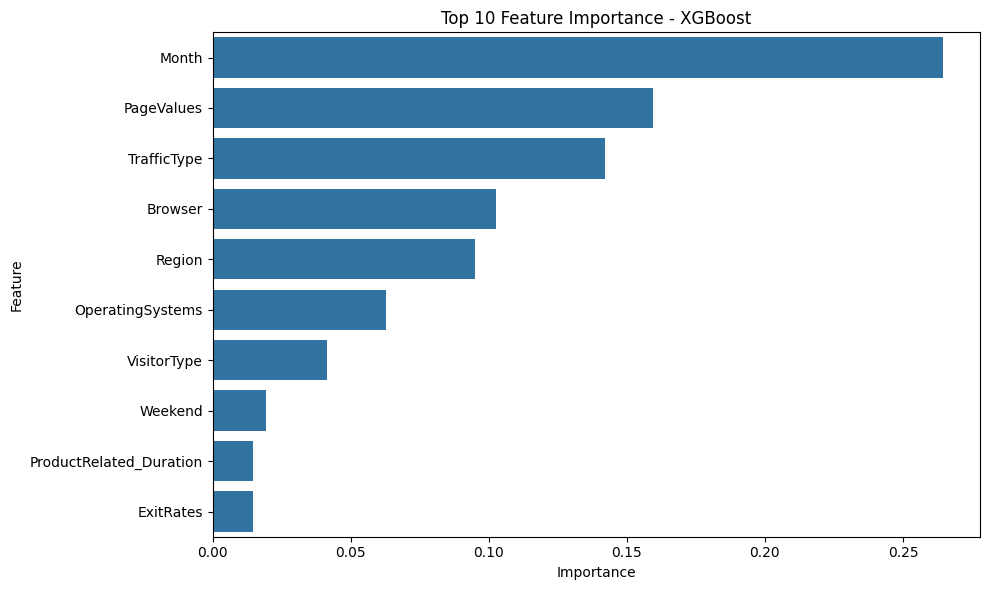

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(data=xgb_feature_importance.head(10),x="Importance",y="Feature")

plt.title("Top 10 Feature Importance - XGBoost")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()